# 06b — Displacement Tests: Lag-1 Control and Regime-Free Nulls

**Purpose.** Notebook 05 found that the next index return responds negatively to displacement from an anchor ($\beta < 0$, ETH $t \approx -3.3$). Two explanations were left open:

1. **Mechanical.** $D_t$ contains the latest return $r_t$, and index returns have a lag-1 reversal ($\rho_1 \approx -0.04$). Any variable that loads on $r_t$ inherits a negative slope.
2. **Construction.** Anchors, volatility scaling and overlapping windows can create apparent predictability on paths that have none.

This notebook decides whether displacement carries information **beyond** the lag-1 reversal, before $D_t$ is allowed to define regimes (framework v2.2 §7) or enter a strategy.

**Anchor (framework v2.2 §5.1): the session VWAP of the perpetual**, rebuilt exactly from our own trade aggregates (base-currency weights), with exact random-walk standardization. The index EWMA anchors (and, without nulls, the rolling VWAPs) are kept as secondary diagnostics only.

| Part | Test |
|---|---|
| A | Clock-adjusted scale $\sigma^c_t$ and displacement $D^c_t$ |
| B | Predictive regressions with and without lagged-return controls, 1/3/6-bar horizons, both halves |
| C | Regime-free nulls through the same pipeline: random signs (N0) and AR(3) with bootstrapped innovations (N1) |
| D | Response by displacement size after removing the lag effect |
| E | Persistence statistics (variance ratio, efficiency ratio) against the random-sign null |

All timestamps UTC. The database is opened read-only.

## 1. Environment

In [1]:
from pathlib import Path
import os
import sys
import math
import warnings

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 200)

load_dotenv()
data_root_env = os.getenv("DERIBIT_DATA_ROOT")
if not data_root_env:
    raise RuntimeError("DERIBIT_DATA_ROOT is not defined in the environment/.env file.")
DB_PATH = Path(data_root_env).expanduser().resolve() / "database" / "research.duckdb"
con = duckdb.connect(str(DB_PATH), read_only=True)
con.execute("SET TimeZone = 'UTC'")

# src modules (pure computation; nothing is written)
PROJECT_ROOT = Path(os.getenv("DERIBIT_PROJECT_ROOT", Path.cwd())).resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent and not (PROJECT_ROOT / "src" / "data_engineering").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "src" / "data_engineering").exists():
    raise RuntimeError("Repository not found: start Jupyter inside the repository or set DERIBIT_PROJECT_ROOT.")
sys.path.insert(0, str(PROJECT_ROOT / "src"))
# A kernel that imported src modules before the last git pull keeps the old code;
# drop cached src modules so the repository version is always the one used.
for _m in [m for m in sys.modules if m.split(".")[0] == "data_engineering"]:
    del sys.modules[_m]
from data_engineering.features import regime_inputs as ri
if tuple(int(x) for x in ri.REGIME_INPUT_VERSION.split(".")) < (0, 3):
    raise RuntimeError(f"regime_inputs {ri.REGIME_INPUT_VERSION} loaded from {ri.__file__}: git pull and restart the kernel (needs >= 0.3)")
print(f"src: {PROJECT_ROOT / 'src'} | regime_inputs {ri.REGIME_INPUT_VERSION}")
from data_engineering.modeling.clock_baseline import ClockBaselineSet, FeatureSpec

PERIODS_PER_YEAR = ri.PERIODS_PER_YEAR
SIGMA_HALF_LIFE = 12          # bars, EWMA of squared clock-adjusted returns
N_SIM = int(os.getenv("NB06B_N_SIM", "200"))
RNG = np.random.default_rng(20261006)
print(f"Research DB: {DB_PATH} | simulations per null and asset: {N_SIM}")

src: D:\Projects\deribit_market_data\src | regime_inputs 0.3
Research DB: D:\MarketData\Deribit\database\research.duckdb | simulations per null and asset: 200


## 2. Load states and regime inputs

`regime_input_state` (built by `build_regime_inputs.py`) is used when present; otherwise the same inputs are computed in memory from `time_series_feature_state` with the same `src` code.

In [2]:
cols = set(con.execute("DESCRIBE time_series_feature_state").df()["column_name"])
want = ["state_id", "state_time", "underlying", "session_id", "futures_index_price", "return_5m",
        "realized_vol_1h_annualized", "index_return_input_eligible", "perp_integrity_ok", "vwap",
        "volume_usd", "futures_tradable_mid_price", "is_weekend", "trade_count",
        "known_exchange_event", "integrity_flag_trades_outside_bbo"]
base = con.execute(f"SELECT {', '.join(c for c in want if c in cols)} FROM time_series_feature_state "
                   "ORDER BY underlying, state_time").df()
base["state_time"] = pd.to_datetime(base["state_time"], utc=True)

tables = set(con.execute("SELECT table_name FROM duckdb_tables()").df()["table_name"])
if "regime_input_state" in tables:
    inputs = con.execute("SELECT * FROM regime_input_state").df()
    source = "regime_input_state"
else:
    inputs = ri.compute_regime_inputs(base)
    source = "computed in memory (run build_regime_inputs.py to persist)"
inputs["state_time"] = pd.to_datetime(inputs["state_time"], utc=True)
if "session_vwap_h" not in inputs:
    raise RuntimeError("regime_input_state predates v0.3 (session VWAP anchor): re-run build_regime_inputs.py")
df = base.merge(inputs.drop(columns=["state_time", "underlying", "session_id"]), on="state_id", how="left")
df = df.sort_values(["underlying", "state_time"]).reset_index(drop=True)
df["r"] = pd.to_numeric(df["return_5m"], errors="coerce")
ASSETS = sorted(df["underlying"].unique())
MAJORS = [a for a in ["BTC", "ETH", "SOL", "XRP"] if a in ASSETS]
print(f"Regime inputs: {source}")
print(f"Rows {len(df):,} | assets {ASSETS} | {df.state_time.min()} → {df.state_time.max()} | sessions {df.session_id.nunique()}")

Regime inputs: regime_input_state
Rows 34,272 | assets ['AVAX', 'BTC', 'ETH', 'HYPE', 'SOL', 'TRX', 'XRP'] | 2026-09-19 08:00:00+00:00 → 2026-10-06 07:55:00+00:00 | sessions 17


# Part A — Clock-Adjusted Scale

## 3. Scale and displacement

The clock baseline (src, v0.2) is fitted on the first half of sessions for returns only. It gives a relative volatility factor $f_t$ ($\overline{f^2} = 1$ in training). With $\tilde r_t = r_t / f_t$:

$$
\tilde\sigma_t^2 = \lambda \tilde\sigma_{t-1}^2 + (1-\lambda)\tilde r_t^2, \qquad \lambda = 0.5^{1/12}, \qquad
\sigma^c_t = f_t\,\tilde\sigma_t
$$

restarted on grid gaps (seeded with the first 12 bars' mean square). $\sigma^c_t$ uses returns up to $t$ only.

**Primary displacement: session VWAP** (perpetual, since 08:00 UTC). With base-currency bar volumes $w_i = \text{USD volume}_i / \mathrm{VWAP}_i$ (exact for inverse and linear contracts) and $C_j = \sum_{i \le j} w_i$ within the session:

$$
A_t = \frac{\sum_{i \le t} w_i \mathrm{VWAP}_i}{C_t}, \qquad
D^c_t = \frac{\log P_t - \log A_t}{\sqrt{\sum_{j \le t} (\sigma^c_j)^2 (C_{j-1}^2 + C_{j-1} w_j + w_j^2/3) / C_t^2}}
$$

$P_t$ is the perpetual mid at the bar close. The denominator is the exact variance of the gap for a random walk with trades spread evenly within bars, so $D^c$ has unit variance at every point of the session. Trades enter the VWAP unless the bar has a known exchange event or prints outside the BBO.

**Secondary (diagnostic) anchors** with a fixed horizon $h$: $D^c_t = (\log P_t - \log A_t)/(\sigma^c_t\sqrt{h})$; index EWMA with $h_{\text{eff}}(H)$, rolling VWAP with $h = W/2$.

The response variable is the standardized next return $z_{t+1} = r_{t+1}/\sigma^c_t$, so heteroskedasticity across the clock and across days does not dominate the regressions.

In [3]:
df["session_date"] = ((df["state_time"] - pd.Timedelta(hours=8)).dt.floor("D") + pd.Timedelta(days=1)).dt.strftime("%Y-%m-%d")
dates = sorted(df.loc[df["r"].notna(), "session_date"].unique())
train_dates = set(dates[: len(dates) // 2])
clock = ClockBaselineSet.fit(
    df[["state_id", "state_time", "underlying", "is_weekend", "return_5m"]],
    df["session_date"].isin(train_dates),
    specs=(FeatureSpec("return_5m", "return_5m", transform="log_abs", scale="none"),),
)
adj = clock.transform(df[["state_id", "state_time", "underlying", "is_weekend", "return_5m"]])
df["f_clock"] = adj["return_5m__clock_vol_factor"].to_numpy()
unfitted = sorted(df.loc[df["f_clock"].isna(), "underlying"].unique())
if unfitted:
    print(f"No clock fit for {unfitted}: using f = 1 (raw EWMA scale) for these assets.")
    df["f_clock"] = df["f_clock"].fillna(1.0)
print(f"Training sessions (clock baseline): {min(train_dates)} → {max(train_dates)}")
print(f"Clock baseline {clock.baseline_id}; fitted assets: {sorted({fb.underlying for fb in clock.fitted})}")


def ewma_sigma(r_tilde, contiguous, half_life=SIGMA_HALF_LIFE, seed_bars=12):
    """Causal EWMA volatility of clock-adjusted returns; restarts on gaps or missing returns."""
    lam = 0.5 ** (1.0 / half_life)
    out = np.full(len(r_tilde), np.nan)
    v, n, seed = np.nan, 0, []
    for i, x in enumerate(r_tilde):
        if not contiguous[i] or not np.isfinite(x):
            v, n, seed = np.nan, 0, []
            if not np.isfinite(x):
                continue
        if n < seed_bars:
            seed.append(x * x)
            n += 1
            if n == seed_bars:
                v = float(np.mean(seed))
                out[i] = math.sqrt(v)
            continue
        v = lam * v + (1 - lam) * x * x
        out[i] = math.sqrt(v)
    return out


PRIMARY = "session_vwap"
VWAP_COLS = ["vwap", "volume_usd", "futures_tradable_mid_price"]
if not set(VWAP_COLS) <= set(df.columns):
    raise RuntimeError(f"Session VWAP inputs missing from time_series_feature_state: {sorted(set(VWAP_COLS) - set(df.columns))}")
ANCHORS = {PRIMARY: (None, None, None)}                               # computed exactly in add_scaled
ANCHORS.update({f"ewma_hl{H}": ("ewma_hl%d_gap" % H, ri.ewma_h_eff(H), f"D_ewma_hl{H}_ready") for H in ri.EWMA_HALF_LIVES})
for W in ri.ROLLING_VWAP_WINDOWS:
    if f"rvwap_{W}_gap" in df:
        ANCHORS[f"rvwap_{W}"] = (f"rvwap_{W}_gap", W / 2.0, f"D_rvwap_{W}_ready")


def add_scaled(d, anchors=None):
    """sigma^c, standardized returns and clock-adjusted displacements for one asset frame."""
    anchors = ANCHORS if anchors is None else anchors
    d = d.copy()
    contiguous = np.r_[False, (d["state_time"].diff().iloc[1:] == pd.Timedelta(minutes=5)).to_numpy()]
    rt = (d["r"] / d["f_clock"]).to_numpy(float)
    d["sigma_c"] = ewma_sigma(rt, contiguous) * d["f_clock"].to_numpy()
    same_next = (d["session_id"].shift(-1) == d["session_id"]) & (d["state_time"].shift(-1) - d["state_time"] == pd.Timedelta(minutes=5))
    d["z_next"] = (d["r"].shift(-1) / d["sigma_c"]).where(same_next)
    sig_prev = d["sigma_c"].shift(1).where(pd.Series(contiguous, index=d.index))
    d["z0"] = d["r"] / sig_prev
    d["z1"] = d["z0"].shift(1).where(pd.Series(contiguous, index=d.index))
    d["z2"] = d["z1"].shift(1).where(pd.Series(contiguous, index=d.index))
    for k in [3, 6]:
        fwd = sum(d["r"].shift(-j) for j in range(1, k + 1))
        ok = d["session_id"].shift(-k) == d["session_id"]
        d[f"z_next{k}"] = (fwd / (d["sigma_c"] * math.sqrt(k))).where(ok)
    for name, (gap, h, ready) in anchors.items():
        if name == PRIMARY:
            vw = pd.to_numeric(d["vwap"], errors="coerce").to_numpy(float)
            w = ri.base_volume(pd.to_numeric(d["volume_usd"], errors="coerce").to_numpy(float), vw)
            new_s = np.r_[True, d["session_date"].to_numpy()[1:] != d["session_date"].to_numpy()[:-1]]
            sv = ri.session_vwap_displacement(ri.perp_log_mid(d), vw, w, ri.vwap_trade_gate(d), new_s,
                                              d["sigma_c"].to_numpy(float))
            d[f"Dc_{name}"] = sv["D"]
            d["vwap_h"] = sv["h"]
            continue
        Dc = d[gap] / (d["sigma_c"] * np.sqrt(h))
        d[f"Dc_{name}"] = Dc.where(d[ready].fillna(False).astype(bool) if ready in d else True)
    return d.replace([np.inf, -np.inf], np.nan)


df["session_date"] = ri.session_key(df["state_time"])
df = pd.concat([add_scaled(g) for _, g in df.groupby("underlying")], ignore_index=True)
dcols = [f"Dc_{a}" for a in ANCHORS]
print("Coverage of standardized next return and clock-adjusted displacement (% of states):")
display(df.groupby("underlying")[["z_next"] + dcols].apply(lambda g: g.notna().mean() * 100).round(1))
print("Standard deviation (≈1 if the scale is right):")
display(df.groupby("underlying")[["z_next", "z0"] + dcols].std().round(2))
print("Session VWAP: % of bars whose trades enter, median effective horizon h (bars):")
display(df.groupby("underlying").apply(lambda g: pd.Series({
    "trade_bars_pct": 100 * ri.vwap_trade_gate(g).mean(), "h_median": g["vwap_h"].median()})).round(1))

Training sessions (clock baseline): 2026-09-22 → 2026-09-28
Clock baseline clock_0.2_20260921T0800_20260928T0755_f79f5e85; fitted assets: ['AVAX', 'BTC', 'ETH', 'HYPE', 'SOL', 'TRX', 'XRP']
Coverage of standardized next return and clock-adjusted displacement (% of states):


,z_next,Dc_session_vwap,Dc_ewma_hl6,Dc_ewma_hl12,Dc_ewma_hl24,Dc_rvwap_12,Dc_rvwap_48
underlying,,,,,,,
AVAX,73.3,85.6,72.9,71.4,61.4,68.3,67.8
BTC,73.3,85.6,72.9,71.4,61.4,73.8,73.1
ETH,73.3,85.6,72.9,71.4,61.4,73.8,73.1
HYPE,73.3,85.6,72.9,71.4,61.4,54.5,52.6
SOL,73.3,85.6,72.9,71.4,61.4,73.8,73.1
TRX,73.0,85.2,72.7,71.1,60.9,8.8,5.9
XRP,73.3,85.6,72.9,71.4,61.4,69.4,70.7


Standard deviation (≈1 if the scale is right):


,z_next,z0,Dc_session_vwap,Dc_ewma_hl6,Dc_ewma_hl12,Dc_ewma_hl24,Dc_rvwap_12,Dc_rvwap_48
underlying,,,,,,,,
AVAX,1.09,1.09,0.71,0.85,0.83,0.78,0.65,0.68
BTC,1.10,1.10,0.85,0.83,0.81,0.78,0.69,0.69
ETH,1.11,1.12,0.80,0.79,0.76,0.74,0.68,0.64
HYPE,1.08,1.08,0.81,0.84,0.85,0.86,0.74,0.78
SOL,1.10,1.11,0.76,0.84,0.82,0.79,0.69,0.65
TRX,1.15,1.15,0.98,0.91,0.96,0.97,0.76,0.84
XRP,1.10,1.10,0.79,0.82,0.79,0.73,0.66,0.64


Session VWAP: % of bars whose trades enter, median effective horizon h (bars):


,trade_bars_pct,h_median
underlying,,
AVAX,80.2,52.4
BTC,87.2,55.8
ETH,87.2,60.0
HYPE,71.2,57.8
SOL,87.2,57.1
TRX,28.6,67.4
XRP,81.4,53.3


# Part B — Predictive Regressions

## 4. Does displacement predict beyond lagged returns?

Per asset and anchor, with Newey–West standard errors (12 lags; $h + 12$ for multi-bar targets):

$$
\textbf{M1:}\; z_{t+1} = a + \beta D^c_t + e_{t+1}
\qquad
\textbf{M2:}\; z_{t+1} = a + \beta D^c_t + \textstyle\sum_{k=0}^{2}\rho_k z_{t-k} + e_{t+1}
$$

$z_t = r_t/\sigma^c_{t-1}$. If the Notebook 05 slope is the lag-1 reversal, $\beta$ shrinks toward zero in M2 while $\rho_0 < 0$. The 3- and 6-bar targets $z^{(k)}_{t} = \sum_{j=1}^{k} r_{t+j}/(\sigma^c_t\sqrt{k})$ test whether the response builds up over time (reversion toward the anchor) or is a one-bar effect. Next returns crossing 08:00 are excluded.

In [4]:
def ols_hac(y, X, lags=12):
    d = pd.concat([y.rename("y"), X], axis=1).dropna()
    if len(d) < 200:
        return None, 0
    Y = d["y"].to_numpy()
    A = np.column_stack([np.ones(len(d)), d.drop(columns="y").to_numpy()])
    beta, *_ = np.linalg.lstsq(A, Y, rcond=None)
    u = Y - A @ beta
    XtX_inv = np.linalg.pinv(A.T @ A)
    S = (A * u[:, None]).T @ (A * u[:, None])
    for L in range(1, lags + 1):
        w = 1 - L / (lags + 1)
        G = (A[L:] * u[L:, None]).T @ (A[:-L] * u[:-L, None])
        S += w * (G + G.T)
    se = np.sqrt(np.clip(np.diag(XtX_inv @ S @ XtX_inv), 0, None))
    return pd.DataFrame({"coef": beta, "se": se, "t": beta / np.where(se > 0, se, np.nan)},
                        index=["const"] + list(X.columns)), len(d)


LAGS = ["z0", "z1", "z2"]
TARGETS = {"1": ("z_next", 12), "3": ("z_next3", 15), "6": ("z_next6", 18)}


def response_table(d, anchors=ANCHORS):
    rows = []
    for asset, g in d.groupby("underlying"):
        for a in anchors:
            D = g[f"Dc_{a}"]
            for hz, (target, lags) in TARGETS.items():
                for model, X in [("M1", D.rename("D").to_frame()),
                                 ("M2", pd.concat([D.rename("D"), g[LAGS]], axis=1))]:
                    est, n = ols_hac(g[target], X, lags=lags)
                    if est is None:
                        continue
                    row = {"underlying": asset, "anchor": a, "horizon": hz, "model": model, "n": n,
                           "beta": est.loc["D", "coef"], "t_beta": est.loc["D", "t"]}
                    if model == "M2":
                        row["rho0"], row["t_rho0"] = est.loc["z0", "coef"], est.loc["z0", "t"]
                    rows.append(row)
    return pd.DataFrame(rows)


resp = response_table(df)
one = resp[resp["horizon"] == "1"]
print("t-statistic of beta, next bar: M1 (D alone) vs M2 (D + three lagged returns)")
display(one.pivot_table(index="anchor", columns=["model", "underlying"], values="t_beta").round(2))
print("Lag-1 coefficient rho0 in M2 (t):")
display(one[one.model == "M2"].pivot_table(index="anchor", columns="underlying", values="t_rho0").round(2))
print("t-statistic of beta in M2 by horizon (bars):")
display(resp[resp.model == "M2"].pivot_table(index=["anchor", "horizon"], columns="underlying", values="t_beta").round(2))

t-statistic of beta, next bar: M1 (D alone) vs M2 (D + three lagged returns)


model           M1                                        M2                                    
underlying    AVAX   BTC   ETH  HYPE   SOL   TRX   XRP  AVAX   BTC   ETH  HYPE   SOL   TRX   XRP
anchor                                                                                          
ewma_hl12    -0.88 -1.85 -3.43 -1.75 -2.02  1.12 -2.14  0.25 -0.87 -1.66 -1.16 -1.08  1.47 -1.64
ewma_hl24    -0.82 -1.41 -2.66 -1.37 -1.49  0.85 -1.95 -0.27 -0.88 -1.53 -0.90 -1.10  1.19 -1.77
ewma_hl6     -0.92 -2.05 -3.77 -2.38 -2.04  0.99 -2.14  0.71 -1.12 -1.85 -1.91 -1.30  1.73 -1.68
rvwap_12     -1.44 -1.53 -2.72 -1.13 -0.92 -0.59 -1.57  0.37 -0.44 -0.81 -1.85 -0.13  0.64 -0.59
rvwap_48      0.47 -1.48 -2.59 -0.09 -1.11  0.98 -1.13  1.24 -0.75 -1.30 -0.17 -0.68  1.31 -0.51
session_vwap -1.08 -0.51 -1.85 -1.71 -1.36  1.09 -0.77 -0.48 -0.05 -0.98 -1.42 -1.02  1.43 -0.47

Lag-1 coefficient rho0 in M2 (t):


underlying,AVAX,BTC,ETH,HYPE,SOL,TRX,XRP
anchor,,,,,,,
ewma_hl12,-1.91,-1.16,-1.44,-1.17,-0.53,-1.67,-0.95
ewma_hl24,-1.25,-1.24,-1.48,-1.29,-0.79,-0.96,-1.34
ewma_hl6,-1.94,-0.21,-0.60,-0.30,0.23,-1.89,-0.26
rvwap_12,-1.65,-0.51,-1.21,0.19,-0.23,-1.11,-0.52
rvwap_48,-1.46,-0.67,-1.45,-1.07,-0.13,-1.57,-1.16
session_vwap,-1.55,-0.91,-1.77,-1.01,-0.15,-1.65,-1.02


t-statistic of beta in M2 by horizon (bars):


underlying            AVAX   BTC   ETH  HYPE   SOL   TRX   XRP
anchor       horizon                                          
ewma_hl12    1        0.25 -0.87 -1.66 -1.16 -1.08  1.47 -1.64
             3        0.25 -0.40 -1.29 -0.84 -0.80  1.80 -0.92
             6       -0.12 -0.28 -1.27 -0.70 -0.94  1.80 -0.89
ewma_hl24    1       -0.27 -0.88 -1.53 -0.90 -1.10  1.19 -1.77
             3       -0.39 -0.39 -1.14 -0.68 -1.02  1.44 -1.12
             6       -0.50 -0.10 -0.90 -0.45 -0.90  1.27 -0.84
ewma_hl6     1        0.71 -1.12 -1.85 -1.91 -1.30  1.73 -1.68
             3        0.80 -0.52 -1.51 -1.53 -0.91  2.02 -0.86
             6        0.38 -0.36 -1.36 -1.24 -1.04  1.96 -0.75
rvwap_12     1        0.37 -0.44 -0.81 -1.85 -0.13  0.64 -0.59
             3        0.33 -0.36 -0.71 -1.35 -0.23  0.95 -0.05
             6        0.13 -0.55 -0.82 -1.58 -0.63  0.67 -0.08
rvwap_48     1        1.24 -0.75 -1.30 -0.17 -0.68  1.31 -0.51
             3        1.12 -0.56 -1.07  0.02 -0.58  1.86 -0.06
             6        0.83 -0.53 -1.03 -0.30 -0.64  2.62 -0.11
session_vwap 1       -0.48 -0.05 -0.98 -1.42 -1.02  1.43 -0.47
             3       -0.48 -0.11 -0.88 -1.39 -1.02  1.49 -0.37
             6       -0.74 -0.30 -0.88 -1.48 -1.04  1.24 -0.13

## 5. Stability across halves

The same M2 regression on each half of the sessions. A real effect keeps its sign; the second half is also the out-of-sample half of the clock baseline.

In [5]:
halves = df.assign(half=np.where(df["session_date"].isin(train_dates), "first", "second"))
rows = []
for half, g in halves.groupby("half"):
    t = response_table(g)
    t = t[(t.horizon == "1") & (t.model == "M2")].assign(half=half)
    rows.append(t)
stability = pd.concat(rows, ignore_index=True)
display(stability.pivot_table(index="anchor", columns=["half", "underlying"], values="t_beta").round(2))

half         first                                     second                                    
underlying    AVAX   BTC   ETH  HYPE   SOL   TRX   XRP   AVAX   BTC   ETH  HYPE   SOL   TRX   XRP
anchor                                                                                           
ewma_hl12     0.46 -1.63 -1.48 -1.72 -1.34  1.46 -0.97  -0.27 -0.05 -1.01 -0.29 -0.41  0.56 -1.37
ewma_hl24     0.44 -1.31 -0.97 -1.17 -1.06  1.52 -1.29  -1.08 -0.26 -1.22 -0.31 -0.65  0.19 -1.23
ewma_hl6      0.61 -1.72 -1.89 -2.02 -1.48  1.55 -0.87   0.31 -0.16 -0.87 -0.92 -0.45  0.80 -1.55
rvwap_12      0.65 -0.97 -0.96 -1.89 -0.83   NaN  0.87  -0.20  0.20 -0.17 -0.89  0.74  0.25 -1.56
rvwap_48      1.26 -1.86 -1.14 -1.31 -1.03   NaN -0.46   0.22  0.17 -0.79  0.43 -0.12   NaN -0.35
session_vwap -0.16 -0.38 -0.82 -2.06 -0.81  1.59 -0.15  -0.62  0.30 -0.55 -0.30 -0.60  0.03 -0.51

# Part C — Regime-Free Nulls

## 6. Simulated paths through the same pipeline

For each asset, simulated returns $r^*_t$ replace $r_t$ on the real grid (missing returns stay missing), and **everything downstream is recomputed** with the same code: index path $\log I^*_t = \sum r^*$; perpetual mid $\log P^*_t = \log I^*_t + b_t$ with the real basis $b_t$; bar VWAPs as Brownian-bridge averages between each bar's start and end prices; the session VWAP with the real base-currency volumes and the real trade and price gates; EWMA anchors (restarted at 08:00 and on gaps); $f_t$ (deterministic, unchanged), $\sigma^c_t$, $D^c_t$, $z$, and the M1/M2 regressions.

- **N0, random signs:** $r^*_t = s_t |r_t|$, $s_t = \pm 1$ i.i.d. Keeps the exact volatility path (clock, clustering, jumps), removes all sign dependence. Any $\beta \neq 0$ under N0 is construction bias.
- **N1, AR(3) without anchors:** $u_t = \sum_{k=1}^{3}\phi_k u_{t-k} + \varepsilon_t$ fitted to the real standardized returns $z_t$, innovations resampled from the fitted residuals; $r^*_t = \sigma^c_{t-1} u_t$. Keeps the short-range reversal, has no anchor effect by construction. **If the real $\beta$ (M1) lies inside N1, displacement adds nothing beyond lagged returns.**

The session VWAP is simulated as above (volume and gates real, prices simulated); the rolling VWAPs are not simulated (diagnostic anchors). Empirical two-sided p-values: $p = \min\{1, 2\min(\Pr^*(\beta^* \le \hat\beta), \Pr^*(\beta^* \ge \hat\beta))\}$ with $N_{sim}$ paths. Resolution is $2/N_{sim}$ (0.01 at 200 paths); with fewer paths (set `NB06B_N_SIM`) a p-value of 0 only means "beyond all simulated paths". Validated on synthetic data: pure random walks stay inside both nulls (p 0.18–0.98 at 100 paths) and a planted anchor reversion is rejected under both.

In [6]:
EWMA_ANCHORS = [a for a in ANCHORS if a.startswith("ewma_")]
NULL_ANCHORS = [PRIMARY] + EWMA_ANCHORS


def fast_ewma_gap(log_i, restart, half_life):
    """Vectorized per-segment EWMA gap; equals regime_inputs.ewma_anchor (checked below)."""
    lam = 0.5 ** (1.0 / half_life)
    seg = np.cumsum(restart | ~np.isfinite(log_i))
    s = pd.Series(log_i)
    a = s.groupby(seg).transform(lambda x: x.ewm(alpha=1 - lam, adjust=False, ignore_na=False).mean())
    a[~np.isfinite(log_i)] = np.nan
    return log_i - a.to_numpy()


def sim_inputs(g, r_star):
    """Rebuild index, anchors and scaled quantities from simulated returns for one asset frame."""
    keep = ["state_id", "state_time", "underlying", "session_id", "session_date", "f_clock", "perp_integrity_ok",
            "trade_count", "known_exchange_event", "integrity_flag_trades_outside_bbo"]
    d = g[[c for c in keep if c in g]].copy()
    d["r"] = r_star
    log_i = np.where(np.isfinite(r_star), np.nancumsum(np.where(np.isfinite(r_star), r_star, 0.0)), np.nan)
    contiguous = np.r_[False, (d["state_time"].diff().iloc[1:] == pd.Timedelta(minutes=5)).to_numpy()]
    # simulated perpetual and session VWAP inputs: real basis, volumes and gates
    sig = ewma_sigma(r_star / d["f_clock"].to_numpy(), contiguous) * d["f_clock"].to_numpy()
    li_full = np.cumsum(np.where(np.isfinite(r_star), r_star, 0.0))
    real_mid = ri.perp_log_mid(g)
    idx = pd.to_numeric(g["futures_index_price"], errors="coerce").to_numpy(float)
    basis = pd.Series(real_mid - np.log(np.where(idx > 0, idx, np.nan))).ffill()
    basis = basis.fillna(basis.median() if basis.notna().any() else 0.0).to_numpy()
    lp, vw_star = ri.synthetic_perp_path(li_full, basis, sig, RNG)
    w_real = ri.base_volume(pd.to_numeric(g["volume_usd"], errors="coerce").to_numpy(float),
                            pd.to_numeric(g["vwap"], errors="coerce").to_numpy(float))
    d["futures_tradable_mid_price"] = np.where(np.isfinite(real_mid), np.exp(lp), np.nan)
    d["vwap"] = np.where(ri.vwap_trade_gate(g), vw_star, np.nan)
    d["volume_usd"] = w_real * vw_star
    new_sess = np.r_[True, d["session_id"].to_numpy()[1:] != d["session_id"].to_numpy()[:-1]]
    restart = new_sess | ~contiguous
    for name in EWMA_ANCHORS:
        H = int(name.split("hl")[1])
        d[f"ewma_hl{H}_gap"] = fast_ewma_gap(log_i, restart, H)
        age = pd.Series(1, index=d.index).groupby(np.cumsum(restart | ~np.isfinite(log_i))).cumsum()
        d[f"D_ewma_hl{H}_ready"] = (age >= H).to_numpy()
    return add_scaled(d, {k: v for k, v in ANCHORS.items() if k in NULL_ANCHORS})


# check: vectorized EWMA equals the src recursion on real data
g0 = df[df.underlying == ASSETS[0]]
li = g0["log_index"].to_numpy(float)
cont0 = np.r_[False, (g0["state_time"].diff().iloc[1:] == pd.Timedelta(minutes=5)).to_numpy()]
ns0 = np.r_[True, g0["session_id"].to_numpy()[1:] != g0["session_id"].to_numpy()[:-1]]
src_a, _ = ri.ewma_anchor(li, ns0 | ~cont0, 12)
assert np.allclose(li - src_a, fast_ewma_gap(li, ns0 | ~cont0, 12), equal_nan=True), "EWMA mismatch"
print("Vectorized EWMA matches src recursion.")


def betas(d):
    out = {}
    for a in NULL_ANCHORS:
        D = d[f"Dc_{a}"]
        for model, X in [("M1", D.rename("D").to_frame()), ("M2", pd.concat([D.rename("D"), d[LAGS]], axis=1))]:
            dd = pd.concat([d["z_next"].rename("y"), X], axis=1).dropna()
            if len(dd) < 200:
                continue
            A = np.column_stack([np.ones(len(dd)), dd.drop(columns="y").to_numpy()])
            b, *_ = np.linalg.lstsq(A, dd["y"].to_numpy(), rcond=None)
            out[(a, model)] = b[1]
    return out


def fit_ar(z, p=3):
    z = pd.Series(z)
    X = pd.concat([z.shift(k) for k in range(1, p + 1)], axis=1)
    dd = pd.concat([z.rename("y"), X], axis=1).dropna()
    A = np.column_stack([np.ones(len(dd)), dd.drop(columns="y").to_numpy()])
    b, *_ = np.linalg.lstsq(A, dd["y"].to_numpy(), rcond=None)
    resid = dd["y"].to_numpy() - A @ b
    return b[1:], resid - resid.mean()


null_rows, real_rows = [], []
for asset, g in df.groupby("underlying"):
    g = g.reset_index(drop=True)
    real = betas(g)
    for (a, m), b in real.items():
        real_rows.append({"underlying": asset, "anchor": a, "model": m, "beta": b})
    r = g["r"].to_numpy(float)
    finite = np.isfinite(r)
    phi, resid = fit_ar(g["z0"].to_numpy(float))
    sig_prev = g["sigma_c"].shift(1).to_numpy(float)
    vol_path = np.where(np.isfinite(sig_prev), sig_prev, np.nanmedian(sig_prev))
    for b_i in range(N_SIM):
        # N0: random signs on the real magnitudes
        s = RNG.choice([-1.0, 1.0], size=len(r))
        res0 = betas(sim_inputs(g, np.where(finite, s * np.abs(r), np.nan)))
        # N1: AR(3) in standardized returns, bootstrapped innovations
        e = RNG.choice(resid, size=len(r) + 50)
        u = np.zeros(len(r) + 50)
        for t_ in range(3, len(u)):
            u[t_] = phi[0] * u[t_ - 1] + phi[1] * u[t_ - 2] + phi[2] * u[t_ - 3] + e[t_]
        res1 = betas(sim_inputs(g, np.where(finite, vol_path * u[50:], np.nan)))
        for null, res in [("N0", res0), ("N1", res1)]:
            for (a, m), b in res.items():
                null_rows.append({"underlying": asset, "anchor": a, "model": m, "null": null, "sim": b_i, "beta": b})
    print(f"{asset}: {N_SIM} paths per null done | AR(3) phi = {np.round(phi, 3)}")

nulls = pd.DataFrame(null_rows)
real_b = pd.DataFrame(real_rows)

Vectorized EWMA matches src recursion.
AVAX: 200 paths per null done | AR(3) phi = [-0.029 -0.021 -0.023]
BTC: 200 paths per null done | AR(3) phi = [-0.018 -0.028  0.007]
ETH: 200 paths per null done | AR(3) phi = [-0.033 -0.01  -0.034]
HYPE: 200 paths per null done | AR(3) phi = [-0.024 -0.001 -0.008]
SOL: 200 paths per null done | AR(3) phi = [-0.007 -0.005 -0.016]
TRX: 200 paths per null done | AR(3) phi = [-0.02  -0.008  0.003]
XRP: 200 paths per null done | AR(3) phi = [-0.025  0.005 -0.017]


Real beta against regime-free nulls (next bar). p < 0.05: outside the null.


null                  N0                                        N1                                    
underlying          AVAX   BTC   ETH  HYPE   SOL   TRX   XRP  AVAX   BTC   ETH  HYPE   SOL   TRX   XRP
anchor       model                                                                                    
ewma_hl12    M1     0.24  0.05  0.00  0.13  0.07  0.24  0.03  0.80  0.32  0.06  0.44  0.15  0.08  0.09
             M2     0.76  0.39  0.13  0.31  0.31  0.08  0.04  0.60  0.44  0.11  0.39  0.27  0.05  0.06
ewma_hl24    M1     0.27  0.13  0.01  0.26  0.14  0.30  0.02  0.83  0.30  0.11  0.46  0.21  0.18  0.05
             M2     0.70  0.40  0.14  0.43  0.26  0.16  0.05  0.82  0.37  0.16  0.46  0.20  0.16  0.03
ewma_hl6     M1     0.28  0.03  0.00  0.02  0.08  0.26  0.04  0.47  0.35  0.06  0.23  0.21  0.09  0.13
             M2     0.41  0.30  0.05  0.05  0.22  0.08  0.09  0.34  0.40  0.10  0.12  0.18  0.01  0.07
session_vwap M1     0.24  0.69  0.12  0.20  0.19  0.15  0.52  0.59  0.88  0.31  0.27  0.21  0.09  0.72
             M2     0.55  0.84  0.37  0.26  0.38  0.09  0.84  0.61  0.92  0.41  0.20  0.23  0.05  0.77

,underlying,anchor,model,null,beta_real,null_median,null_p05,null_p95,p_value
0,AVAX,ewma_hl12,M1,N0,-0.0217,0.0001,-0.0326,0.0289,0.24
1,AVAX,ewma_hl12,M1,N1,-0.0217,-0.0302,-0.0707,0.0088,0.80
2,AVAX,ewma_hl12,M2,N0,0.0075,0.0002,-0.0357,0.0343,0.76
3,AVAX,ewma_hl12,M2,N1,0.0075,-0.0041,-0.0480,0.0316,0.60
4,AVAX,ewma_hl24,M1,N0,-0.0241,0.0001,-0.0330,0.0317,0.27
...,...,...,...,...,...,...,...,...,...
107,XRP,ewma_hl6,M2,N1,-0.0525,-0.0021,-0.0445,0.0433,0.07
108,XRP,session_vwap,M1,N0,-0.0180,-0.0048,-0.0406,0.0221,0.52
109,XRP,session_vwap,M1,N1,-0.0180,-0.0089,-0.0518,0.0213,0.72
110,XRP,session_vwap,M2,N0,-0.0116,-0.0063,-0.0418,0.0226,0.84


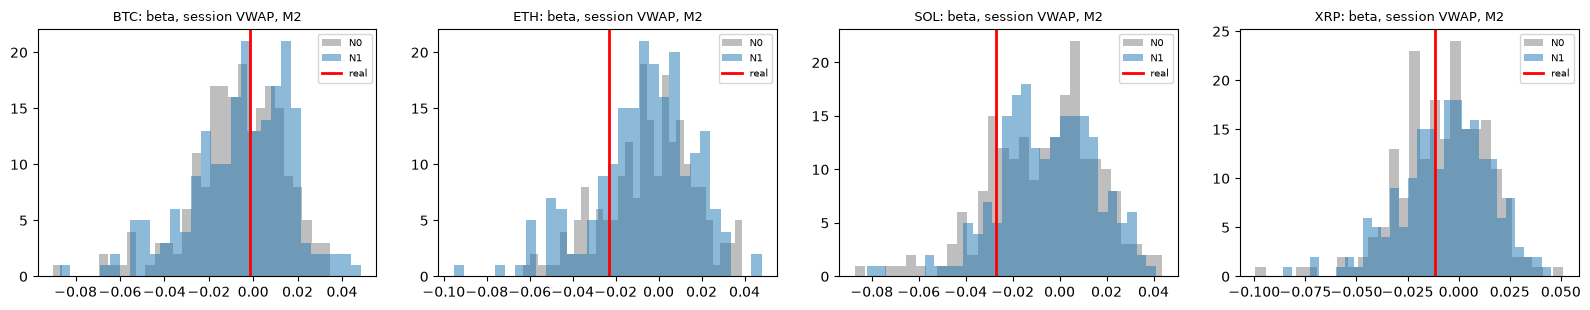

In [7]:
def empirical_p(real, sims):
    lo = (sims <= real).mean()
    hi = (sims >= real).mean()
    return min(1.0, 2 * min(lo, hi))


rows = []
for (asset, a, m, null), s in nulls.groupby(["underlying", "anchor", "model", "null"]):
    rb = real_b[(real_b.underlying == asset) & (real_b.anchor == a) & (real_b.model == m)]["beta"]
    if rb.empty:
        continue
    rows.append({"underlying": asset, "anchor": a, "model": m, "null": null, "beta_real": rb.iloc[0],
                 "null_median": s["beta"].median(), "null_p05": s["beta"].quantile(0.05),
                 "null_p95": s["beta"].quantile(0.95), "p_value": empirical_p(rb.iloc[0], s["beta"].to_numpy())})
null_test = pd.DataFrame(rows)
print("Real beta against regime-free nulls (next bar). p < 0.05: outside the null.")
display(null_test.pivot_table(index=["anchor", "model"], columns=["null", "underlying"], values="p_value").round(3))
display(null_test.round(4))

if MAJORS:
    fig, axes = plt.subplots(1, len(MAJORS), figsize=(4 * len(MAJORS), 3.2), squeeze=False)
    for ax, asset in zip(axes[0], MAJORS):
        for null, colr in [("N0", "tab:gray"), ("N1", "tab:blue")]:
            s = nulls[(nulls.underlying == asset) & (nulls.anchor == PRIMARY) & (nulls.model == "M2") & (nulls.null == null)]
            ax.hist(s["beta"], bins=30, alpha=0.5, color=colr, label=null)
        rb = real_b[(real_b.underlying == asset) & (real_b.anchor == PRIMARY) & (real_b.model == "M2")]["beta"]
        if len(rb):
            ax.axvline(rb.iloc[0], color="red", lw=2, label="real")
        ax.set_title(f"{asset}: beta, session VWAP, M2", fontsize=9)
        ax.legend(fontsize=7)
    plt.tight_layout(); plt.show()

# Part D — Response by Displacement Size

## 7. Decile response net of the lag effect

The standardized next return is residualized on the three lagged returns (per asset), then averaged within deciles of $D^c_t$ (session VWAP). A real anchor effect shows up as a monotone or tail pattern **after** the lag effect is removed. Pooled over the majors, deciles computed per asset.

underlying,AVAX,BTC,ETH,HYPE,SOL,TRX,XRP
decile,,,,,,,
0,0.019,-0.006,0.017,0.027,-0.042,-0.116,-0.025
1,0.004,0.041,-0.012,-0.024,0.092,0.050,0.026
2,-0.036,-0.027,0.054,0.005,0.075,0.033,-0.054
3,0.069,0.078,-0.040,0.021,-0.089,0.062,-0.029
4,-0.018,-0.068,-0.001,0.061,0.062,-0.010,0.084
5,-0.061,-0.007,0.035,-0.029,-0.102,-0.009,0.053
6,-0.040,-0.111,0.073,0.007,0.071,-0.068,0.026
7,-0.022,0.104,0.009,0.015,0.060,-0.024,-0.021
8,0.137,-0.019,-0.036,0.048,-0.077,0.009,0.034


,mean_D,raw,net,se
decile,,,,
0,-1.468,0.023,-0.014,0.030
1,-0.869,0.069,0.037,0.027
2,-0.566,0.041,0.012,0.028
3,-0.340,0.008,-0.020,0.029
4,-0.132,0.044,0.019,0.031
5,0.073,0.019,-0.005,0.028
6,0.276,0.038,0.015,0.028
7,0.503,0.058,0.038,0.031
8,0.751,-0.008,-0.024,0.032


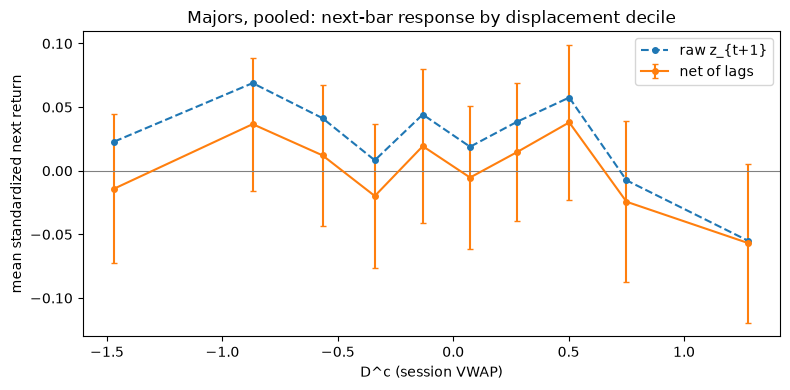

In [8]:
dec_rows = []
for asset, g in df.groupby("underlying"):
    d = g[["z_next", f"Dc_{PRIMARY}"] + LAGS].dropna()
    if len(d) < 1000:
        continue
    A = np.column_stack([np.ones(len(d)), d[LAGS].to_numpy()])
    b, *_ = np.linalg.lstsq(A, d["z_next"].to_numpy(), rcond=None)
    d = d.assign(z_resid=d["z_next"].to_numpy() - A @ b,
                 decile=pd.qcut(d[f"Dc_{PRIMARY}"], 10, labels=False, duplicates="drop"))
    s = d.groupby("decile").agg(mean_D=(f"Dc_{PRIMARY}", "mean"), raw=("z_next", "mean"), net=("z_resid", "mean"),
                                se=("z_resid", lambda v: v.std() / math.sqrt(len(v))), n=("z_resid", "size"))
    dec_rows.append(s.assign(underlying=asset).reset_index())
deciles = pd.concat(dec_rows, ignore_index=True)
display(deciles.pivot_table(index="decile", columns="underlying", values="net").round(3))
pooled = deciles[deciles.underlying.isin(MAJORS)].groupby("decile").agg(
    mean_D=("mean_D", "mean"), raw=("raw", "mean"), net=("net", "mean"),
    se=("se", lambda s: math.sqrt((s ** 2).sum()) / len(s)))
display(pooled.round(3))
fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(pooled["mean_D"], pooled["raw"], fmt="o--", ms=4, label="raw z_{t+1}")
ax.errorbar(pooled["mean_D"], pooled["net"], yerr=1.96 * pooled["se"], fmt="o-", ms=4, capsize=2, label="net of lags")
ax.axhline(0, color="grey", lw=0.8)
ax.set_xlabel("D^c (session VWAP)"); ax.set_ylabel("mean standardized next return")
ax.set_title("Majors, pooled: next-bar response by displacement decile"); ax.legend()
plt.tight_layout(); plt.show()

# Part E — Persistence Statistics

## 8. Variance ratio and efficiency ratio against the random-sign null

Under N0 (random signs on the real magnitudes) $\mathrm{VR}(q) \approx 1$ and the efficiency ratio has mean about $1/\sqrt{N}$, with dispersion set by the real volatility path. The table compares the real distribution with N0: the share of states above the N0 95th percentile and below the 5th (10% total expected by chance). Persistent or anti-persistent **periods** would show up as excess mass in the tails; a shifted median indicates unconditional persistence or reversal.

In [9]:
stat_cols = [c for c in df.columns if c.startswith(("vr_q", "er_n"))]
rows = []
for asset, g in df.groupby("underlying"):
    g = g.reset_index(drop=True)
    r = g["r"].to_numpy(float)
    finite = np.isfinite(r)
    sims = []
    for _ in range(20):
        s = RNG.choice([-1.0, 1.0], size=len(r))
        sim = g[["state_id", "state_time", "underlying", "session_id", "futures_index_price", "realized_vol_1h_annualized"]].copy()
        sim["return_5m"] = np.where(finite, s * np.abs(r), np.nan)
        sims.append(ri.compute_regime_inputs(sim)[stat_cols])
    sims = pd.concat(sims, ignore_index=True)
    for c in stat_cols:
        real = g[c].dropna()
        if len(real) < 500:
            continue
        lo, hi = sims[c].quantile([0.05, 0.95])
        rows.append({"underlying": asset, "statistic": c, "real_median": real.median(), "null_median": sims[c].median(),
                     "share_above_null_p95": (real > hi).mean(), "share_below_null_p05": (real < lo).mean()})
persistence = pd.DataFrame(rows)
display(persistence.pivot_table(index="statistic", columns="underlying", values=["real_median", "null_median"]).round(3))
display(persistence.pivot_table(index="statistic", columns="underlying", values=["share_above_null_p95", "share_below_null_p05"]).round(3))

null_median                                           real_median                                          
underlying        AVAX    BTC    ETH   HYPE    SOL    TRX    XRP        AVAX    BTC    ETH   HYPE    SOL    TRX    XRP
statistic                                                                                                             
er_n12           0.267  0.273  0.264  0.265  0.268  0.288  0.265       0.249  0.241  0.227  0.248  0.237  0.270  0.241
er_n48           0.129  0.135  0.133  0.133  0.129  0.138  0.125       0.120  0.127  0.113  0.132  0.125  0.134  0.119
vr_q3_n48        0.984  0.992  0.980  0.985  0.981  0.971  0.994       0.917  0.914  0.921  0.974  0.959  0.924  0.932
vr_q6_n48        0.948  0.942  0.941  0.941  0.943  0.929  0.945       0.817  0.839  0.847  0.917  0.914  0.851  0.847

share_above_null_p95                                           share_below_null_p05                                          
underlying                 AVAX    BTC    ETH   HYPE    SOL    TRX    XRP                 AVAX    BTC    ETH   HYPE    SOL    TRX    XRP
statistic                                                                                                                               
er_n12                    0.028  0.030  0.021  0.029  0.029  0.054  0.023                0.054  0.049  0.057  0.050  0.052  0.058  0.051
er_n48                    0.010  0.017  0.014  0.014  0.029  0.079  0.021                0.049  0.061  0.058  0.050  0.046  0.047  0.052
vr_q3_n48                 0.006  0.008  0.004  0.035  0.012  0.044  0.033                0.059  0.057  0.041  0.031  0.033  0.123  0.055
vr_q6_n48                 0.010  0.003  0.000  0.019  0.022  0.060  0.015                0.110  0.062  0.048  0.054  0.057  0.103  0.063

## 9. Interpretation checklist

| Result | Implication |
|---|---|
| §4: $\beta$ loses significance from M1 to M2, $\rho_0 < 0$ significant | The Notebook 05 slope is the lag-1 reversal. $D_t$ adds no unconditional information; any regime use must show conditional $\beta_k \neq 0$ that survives the same control. |
| §4: $\beta$ stays significant in M2 and grows with horizon (3, 6 bars) | Reversion toward the anchor beyond the bar-to-bar effect; the anchor is informative. |
| §5: sign flips between halves | Not stable; do not build on it at this sample size. |
| §6: real $\beta$ inside N0 | Construction bias explains it (scaling, anchor restart, overlap). |
| §6: real $\beta$ outside N0 but inside N1 | Lag-1/short-range reversal explains it; displacement redundant with lagged returns. |
| §6: real $\beta$ outside N1 | Evidence for an anchor effect beyond short-range dependence; candidate for the regime-defining slope. |
| §7: net decile response flat | No tail reversion once lags are removed. |
| §8: tails of VR/ER beyond the N0 bands (> 10% total) | Persistence varies over time: candidate regime information in VR/ER. A shifted median alone is an unconditional effect. |

**Scope.** Unconditional tests on ~15 sessions. A null result here does not rule out offsetting regime-specific responses (mean reversion in some periods, momentum in others); the HSMM null-simulation step (framework §6, b2) tests that conditionally.

In [10]:
displacement_report = {
    "response": resp, "stability": stability, "null_test": null_test,
    "deciles": deciles, "persistence": persistence,
}
for k, v in displacement_report.items():
    print(f"  {k:<12} {len(v):>7,} rows")
con.close()
print("DuckDB connection closed.")

  response         252 rows
  stability         81 rows
  null_test        112 rows
  deciles           70 rows
  persistence       28 rows
DuckDB connection closed.
